In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully!")

Libraries imported successfully!


In [52]:
df = pd.read_csv("../data/sample_dataset.csv")

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (92629, 6)


,Time,BS,Energy,load,ESMODE,TXpower
0,20230101 010000,B_0,64.275037,0.487936,0.0,7.101719
1,20230101 020000,B_0,55.904335,0.344468,0.0,7.101719
2,20230101 030000,B_0,57.698057,0.193766,0.0,7.101719
3,20230101 040000,B_0,55.156951,0.222383,0.0,7.101719
4,20230101 050000,B_0,56.053812,0.175436,0.0,7.101719



Dataset columns:
['Time', 'BS', 'Energy', 'load', 'ESMODE', 'TXpower']

Missing values:
Time       0
BS         0
Energy     0
load       0
ESMODE     0
TXpower    0
dtype: int64


In [53]:
df["Time"] = pd.to_datetime(
    df["Time"],
    format="%Y%m%d %H%M%S",
    errors="coerce"
)

numeric_columns = [
    "Energy",
    "load",
    "ESMODE",
    "TXpower"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=[
        "Time",
        "Energy",
        "load",
        "ESMODE",
        "TXpower",
        "BS"
    ]
)

df = df.sort_values("Time").reset_index(drop=True)

print("Data cleaning complete!")

print("Remaining observations:", len(df))

print("Number of base stations:", df["BS"].nunique())

print(
    "Date range:",
    df["Time"].min(),
    "to",
    df["Time"].max()
)

Data cleaning complete!
Remaining observations: 92629
Number of base stations: 923
Date range: 2023-01-01 01:00:00 to 2023-01-08 00:00:00


In [54]:
df["hour"] = df["Time"].dt.hour
df["day"] = df["Time"].dt.dayofweek
df["month"] = df["Time"].dt.month

# Represent time cyclically
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

df["day_sin"] = np.sin(
    2 * np.pi * df["day"] / 7
)

df["day_cos"] = np.cos(
    2 * np.pi * df["day"] / 7
)

print("Feature engineering complete!")

display(df.head())

Feature engineering complete!


C:\Users\nconc\AppData\Local\Temp\ipykernel_20676\1859617347.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day"] = df["Time"].dt.dayofweek


,Time,BS,Energy,load,ESMODE,TXpower,hour,day,month,hour_sin,hour_cos,day_sin,day_cos
0,2023-01-01 01:00:00,B_0,64.275037,0.487936,0.0,7.101719,1,6,1,0.258819,0.965926,-0.781831,0.62349
1,2023-01-01 01:00:00,B_652,14.200299,0.213140,0.0,6.875934,1,6,1,0.258819,0.965926,-0.781831,0.62349
2,2023-01-01 01:00:00,B_653,13.153961,0.074400,0.0,5.979073,1,6,1,0.258819,0.965926,-0.781831,0.62349
3,2023-01-01 01:00:00,B_113,62.331839,0.492460,0.0,7.101719,1,6,1,0.258819,0.965926,-0.781831,0.62349
4,2023-01-01 01:00:00,B_655,21.076233,0.121980,0.0,6.532138,1,6,1,0.258819,0.965926,-0.781831,0.62349


In [55]:
features = [
    "load",
    "ESMODE",
    "TXpower",
    "BS",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "month"
]

X = df[features]

y = df["Energy"]

numeric_features = [
    "load",
    "ESMODE",
    "TXpower",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "month"
]

categorical_features = ["BS"]

preprocessor = ColumnTransformer([
    (
        "numeric",
        "passthrough",
        numeric_features
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        categorical_features
    )
])

linear_preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_features
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        categorical_features
    )
])

print("Features selected successfully!")

Features selected successfully!


In [56]:
unique_times = np.sort(df["Time"].unique())

split_time = unique_times[
    int(len(unique_times) * 0.8)
]

train_mask = df["Time"] < split_time
test_mask = df["Time"] >= split_time

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training ends:", df.loc[train_mask, "Time"].max())
print("Testing starts:", df.loc[test_mask, "Time"].min())

Training observations: 82949
Testing observations: 9680
Training ends: 2023-01-06 14:00:00
Testing starts: 2023-01-06 15:00:00


In [57]:
models = {
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=6
        ))
    ]),

    "Extra Trees": Pipeline([
        ("preprocessor", preprocessor),
        ("model", ExtraTreesRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=6
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingRegressor(
            max_iter=100,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        ))
    ])
}

results = []
trained_models = {}
predictions_dict = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.time()

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    duration = time.time() - start

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Training Time": duration
    })

    trained_models[name] = model
    predictions_dict[name] = predictions

    print(f"Completed in {duration:.2f} seconds")


# Dummy Baseline
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

results.append({
    "Model": "Dummy Baseline",
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    "R2": r2_score(y_test, baseline_predictions),
    "Training Time": 0
})

predictions_dict["Dummy Baseline"] = baseline_predictions

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")

display(
    results_df.sort_values("MAE").round(4)
)


Training Random Forest...
Completed in 86.76 seconds

Training Extra Trees...
Completed in 387.38 seconds

Training Gradient Boosting...
Completed in 12.00 seconds

MODEL COMPARISON


,Model,MAE,RMSE,R2,Training Time
2,Gradient Boosting,2.4224,3.2244,0.9477,11.9992
0,Random Forest,2.8620,3.9385,0.9220,86.7593
1,Extra Trees,3.1163,4.2345,0.9098,387.3796
3,Dummy Baseline,10.9781,14.1848,-0.0123,0.0000


In [58]:
best_model_name = results_df.loc[
    results_df["MAE"].idxmin(),
    "Model"
]

best_predictions = predictions_dict[best_model_name]

best_model = trained_models[best_model_name]

mae = mean_absolute_error(
    y_test,
    best_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, best_predictions)
)

r2 = r2_score(
    y_test,
    best_predictions
)

print("BEST MODEL:", best_model_name)

print("\nFINAL TEST RESULTS")

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2:", round(r2, 4))

BEST MODEL: Gradient Boosting

FINAL TEST RESULTS
MAE: 2.4224
RMSE: 3.2244
R2: 0.9477


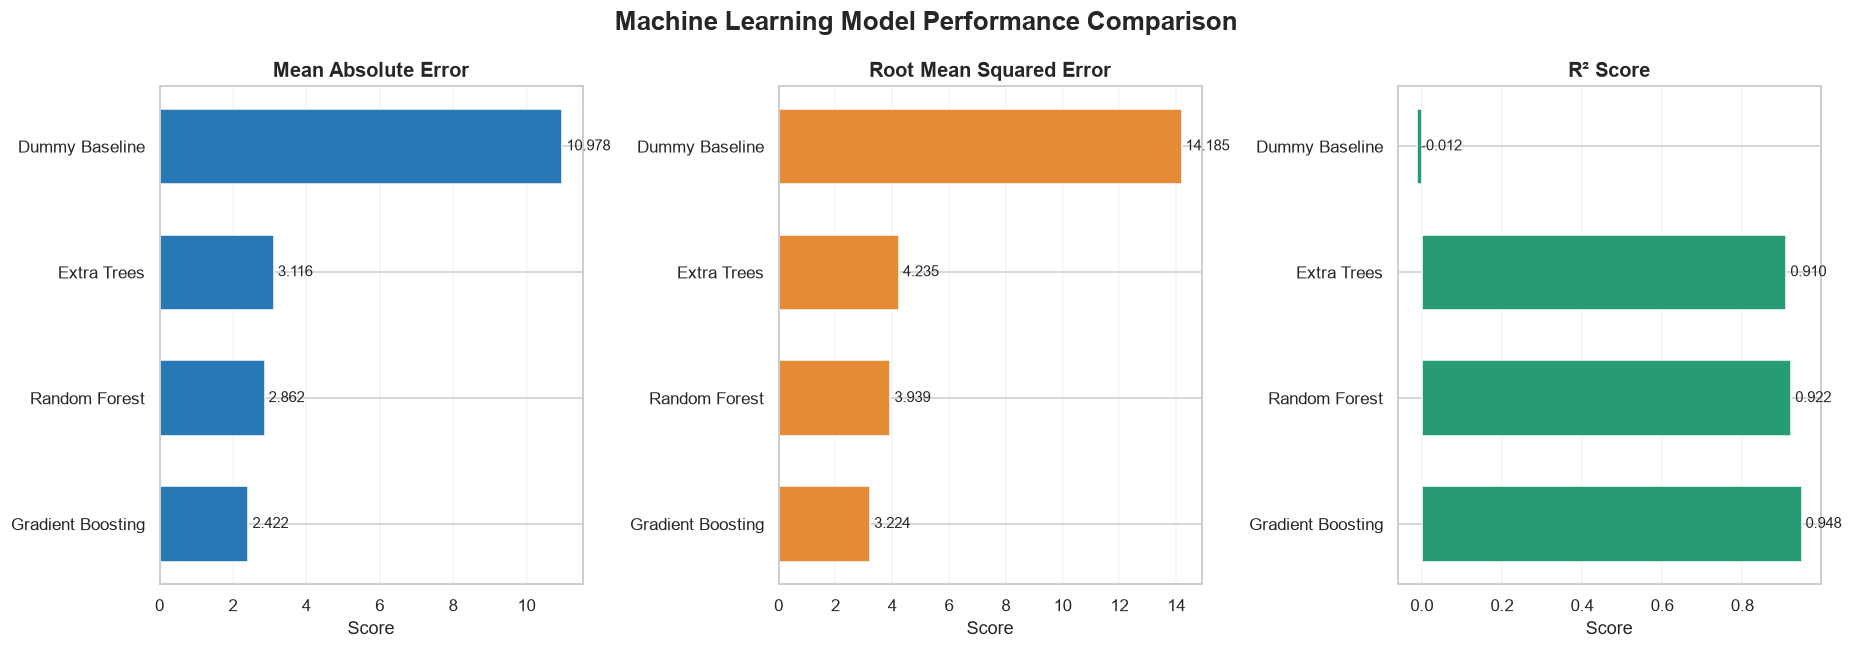

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

metrics = [
    ("MAE", "Mean Absolute Error", "#2878B5", True),
    ("RMSE", "Root Mean Squared Error", "#E58B35", True),
    ("R2", "R² Score", "#269B75", False)
]

for ax, (metric, title, color, ascending) in zip(axes, metrics):

    ordered = results_df.sort_values(
        metric,
        ascending=ascending
    )

    bars = ax.barh(
        ordered["Model"],
        ordered[metric],
        color=color,
        height=0.6
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Score")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    for bar in bars:

        value = bar.get_width()

        ax.text(
            value,
            bar.get_y() + bar.get_height()/2,
            f" {value:.3f}",
            va="center",
            fontsize=10
        )

fig.suptitle(
    "Machine Learning Model Performance Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

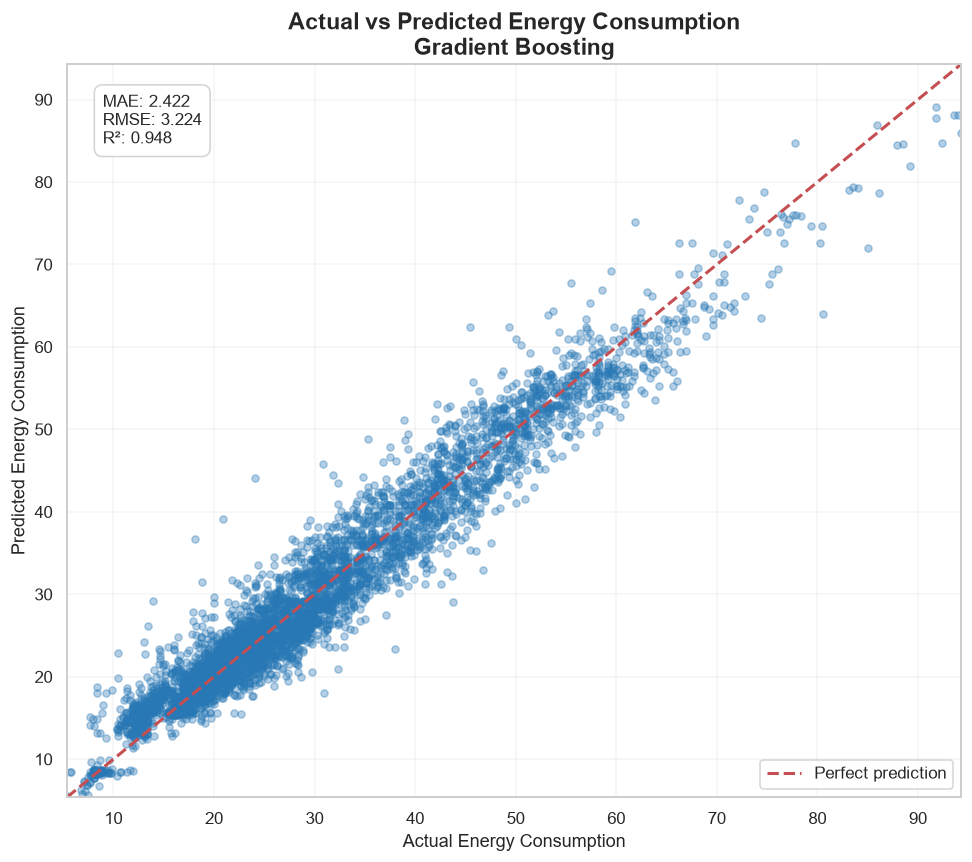

In [60]:
fig, ax = plt.subplots(figsize=(9, 8))

sample_size = min(5000, len(y_test))

rng = np.random.default_rng(42)

indices = rng.choice(
    len(y_test),
    sample_size,
    replace=False
)

actual = np.asarray(y_test)[indices]
predicted = best_predictions[indices]

ax.scatter(
    actual,
    predicted,
    alpha=0.35,
    s=22,
    color="#2878B5"
)

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

ax.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    linewidth=2,
    label="Perfect prediction"
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)

ax.set_xlabel("Actual Energy Consumption", fontsize=12)
ax.set_ylabel("Predicted Energy Consumption", fontsize=12)

ax.set_title(
    f"Actual vs Predicted Energy Consumption\n{best_model_name}",
    fontsize=15,
    fontweight="bold"
)

ax.text(
    0.04,
    0.96,
    f"MAE: {mae:.3f}\nRMSE: {rmse:.3f}\nR²: {r2:.3f}",
    transform=ax.transAxes,
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="lightgray"
    ),
    fontsize=11
)

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

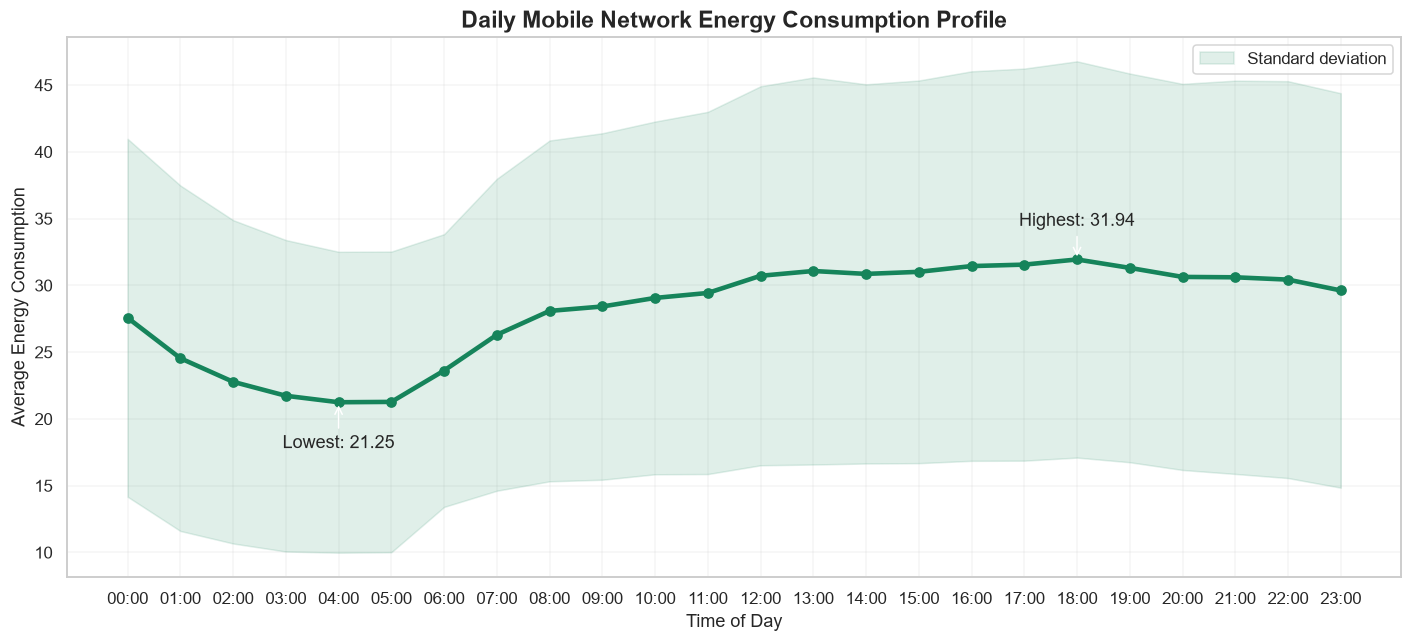

In [61]:
hourly_profile = (
    df.groupby("hour")["Energy"]
    .agg(["mean", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    hourly_profile["hour"],
    hourly_profile["mean"],
    color="#16845B",
    linewidth=3,
    marker="o",
    markersize=6
)

ax.fill_between(
    hourly_profile["hour"],
    hourly_profile["mean"] - hourly_profile["std"],
    hourly_profile["mean"] + hourly_profile["std"],
    color="#16845B",
    alpha=0.13,
    label="Standard deviation"
)

peak = hourly_profile.loc[
    hourly_profile["mean"].idxmax()
]

lowest = hourly_profile.loc[
    hourly_profile["mean"].idxmin()
]

ax.annotate(
    f"Highest: {peak['mean']:.2f}",
    xy=(peak["hour"], peak["mean"]),
    xytext=(0, 22),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

ax.annotate(
    f"Lowest: {lowest['mean']:.2f}",
    xy=(lowest["hour"], lowest["mean"]),
    xytext=(0, -30),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

ax.set_xticks(range(24))
ax.set_xticklabels([
    f"{h:02d}:00" for h in range(24)
])

ax.set_xlabel("Time of Day")
ax.set_ylabel("Average Energy Consumption")

ax.set_title(
    "Daily Mobile Network Energy Consumption Profile",
    fontsize=15,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

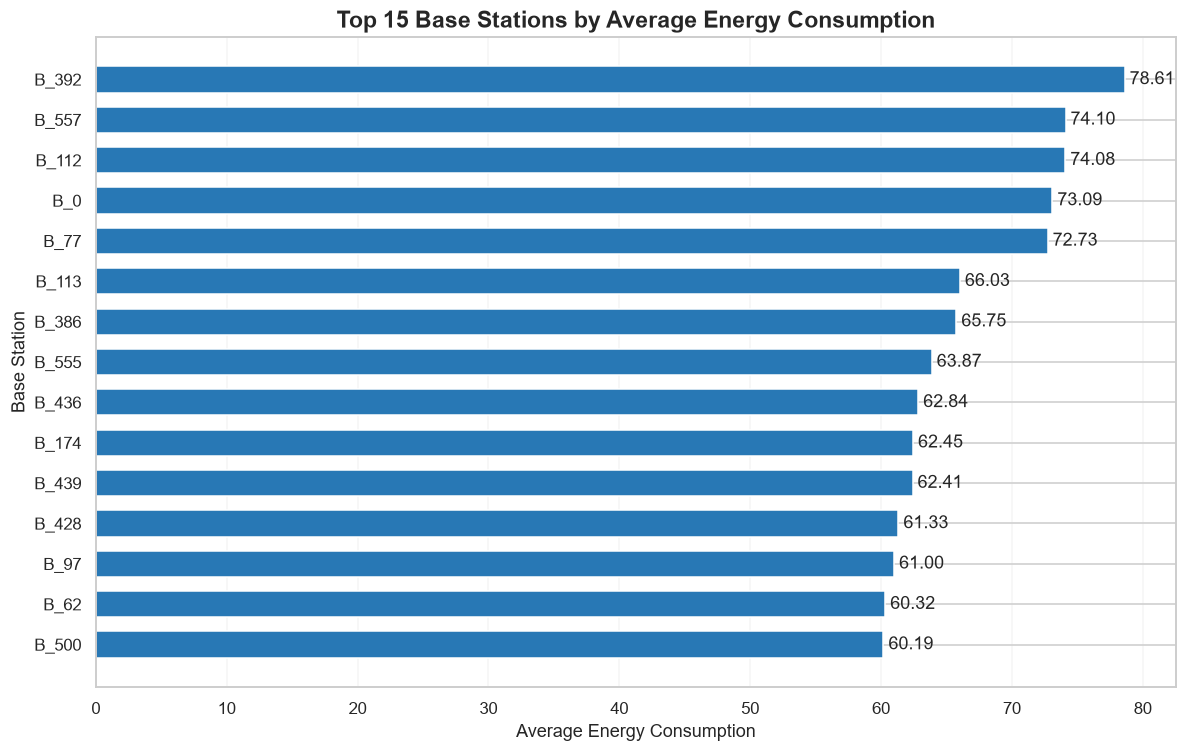

In [62]:
bs_summary = (
    df.groupby("BS")
    .agg(
        Average_Energy=("Energy", "mean"),
        Readings=("Energy", "count")
    )
    .sort_values(
        "Average_Energy",
        ascending=False
    )
)

top_bs = bs_summary.head(15).sort_values(
    "Average_Energy",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_bs.index.astype(str),
    top_bs["Average_Energy"],
    color="#2878B5",
    height=0.65
)

for bar in bars:

    value = bar.get_width()

    ax.text(
        value,
        bar.get_y() + bar.get_height()/2,
        f" {value:.2f}",
        va="center"
    )

ax.set_xlabel("Average Energy Consumption")
ax.set_ylabel("Base Station")

ax.set_title(
    "Top 15 Base Stations by Average Energy Consumption",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [63]:
mode_counts = df["ESMODE"].value_counts().sort_index()

print("ESMODE observation counts:")
display(mode_counts.to_frame("Readings"))

if df["ESMODE"].nunique() <= 12:

    fig, ax = plt.subplots(figsize=(11, 6))

    sns.boxplot(
        data=df,
        x="ESMODE",
        y="Energy",
        hue="ESMODE",
        palette="Set2",
        legend=False,
        showfliers=False,
        width=0.55,
        ax=ax
    )

    ax.set_xlabel("Energy-Saving Mode")
    ax.set_ylabel("Energy Consumption")

    ax.set_title(
        "Energy Consumption Distribution Across ESMODE Settings",
        fontsize=15,
        fontweight="bold"
    )

    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()

else:

    print(
        "ESMODE has more than 12 unique values. "
        "Inspect the variable before selecting a suitable graph."
    )

ESMODE observation counts:


,Readings
ESMODE,
0.000000,87475
0.000278,73
0.000300,1
0.000342,1
0.000394,1
...,...
3.893889,1
3.922222,1
3.955556,1


ESMODE has more than 12 unique values. Inspect the variable before selecting a suitable graph.


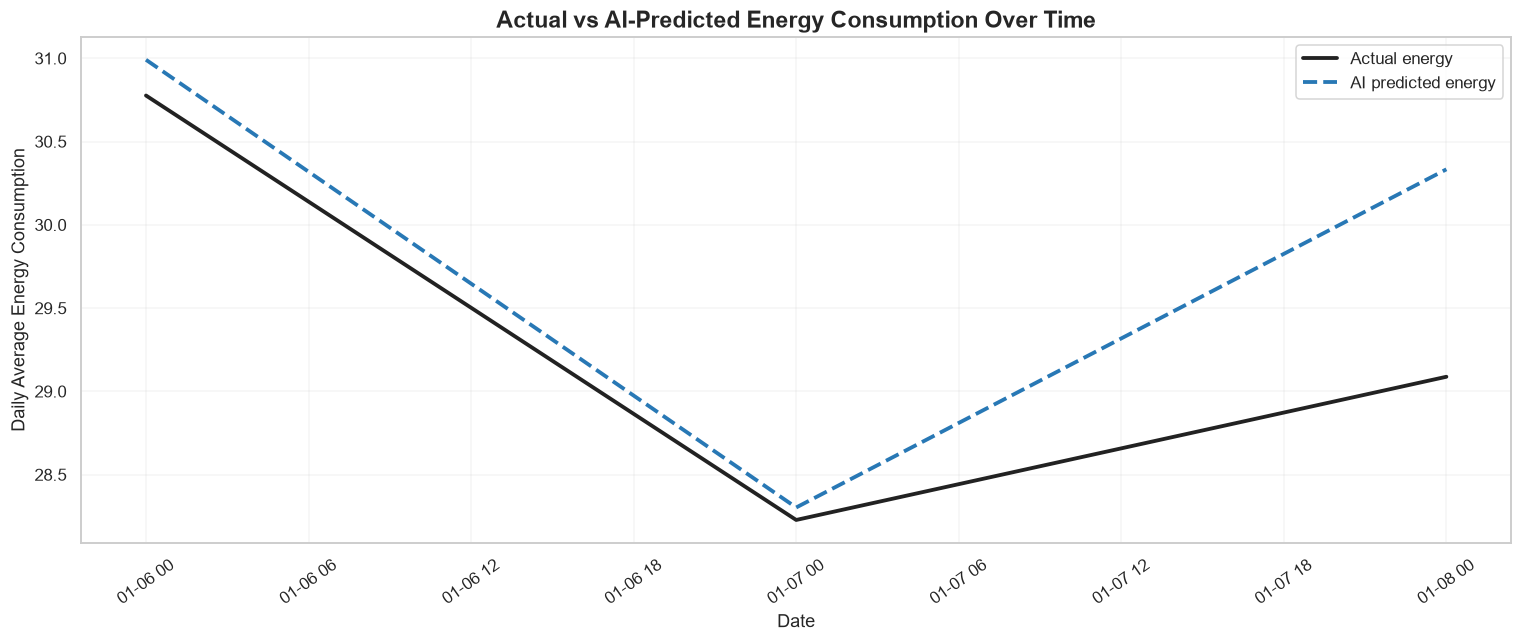

In [64]:
evaluation_df = pd.DataFrame({
    "Time": df.loc[test_mask, "Time"].values,
    "Actual": np.asarray(y_test),
    "Predicted": best_predictions
})

daily_comparison = (
    evaluation_df
    .set_index("Time")[["Actual", "Predicted"]]
    .resample("D")
    .mean()
    .dropna()
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_comparison.index,
    daily_comparison["Actual"],
    color="#222222",
    linewidth=2.5,
    label="Actual energy"
)

ax.plot(
    daily_comparison.index,
    daily_comparison["Predicted"],
    color="#2878B5",
    linewidth=2.5,
    linestyle="--",
    label="AI predicted energy"
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily Average Energy Consumption")

ax.set_title(
    "Actual vs AI-Predicted Energy Consumption Over Time",
    fontsize=15,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.2)

plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [65]:
print("=" * 55)

print("MOBILE NETWORK ENERGY CONSUMPTION ANALYSIS")

print("=" * 55)

print("\nDATASET INFORMATION")

print("Total observations:", len(df))

print("Number of base stations:", df["BS"].nunique())

print("Training observations:", len(X_train))

print("Testing observations:", len(X_test))

print("\nMODEL COMPARISON")

display(
    results_df.sort_values("MAE").round(4)
)

print("\nBEST MODEL")

print(best_model_name)

print("\nFINAL TEST PERFORMANCE")

print("MAE:", round(mae, 4))

print("RMSE:", round(rmse, 4))

print("R²:", round(r2, 4))

print("\nRESEARCH PERIOD")

print("Start:", df["Time"].min())

print("End:", df["Time"].max())

print("=" * 55)

MOBILE NETWORK ENERGY CONSUMPTION ANALYSIS

DATASET INFORMATION
Total observations: 92629
Number of base stations: 923
Training observations: 82949
Testing observations: 9680

MODEL COMPARISON


,Model,MAE,RMSE,R2,Training Time
2,Gradient Boosting,2.4224,3.2244,0.9477,11.9992
0,Random Forest,2.8620,3.9385,0.9220,86.7593
1,Extra Trees,3.1163,4.2345,0.9098,387.3796
3,Dummy Baseline,10.9781,14.1848,-0.0123,0.0000



BEST MODEL
Gradient Boosting

FINAL TEST PERFORMANCE
MAE: 2.4224
RMSE: 3.2244
R²: 0.9477

RESEARCH PERIOD
Start: 2023-01-01 01:00:00
End: 2023-01-08 00:00:00


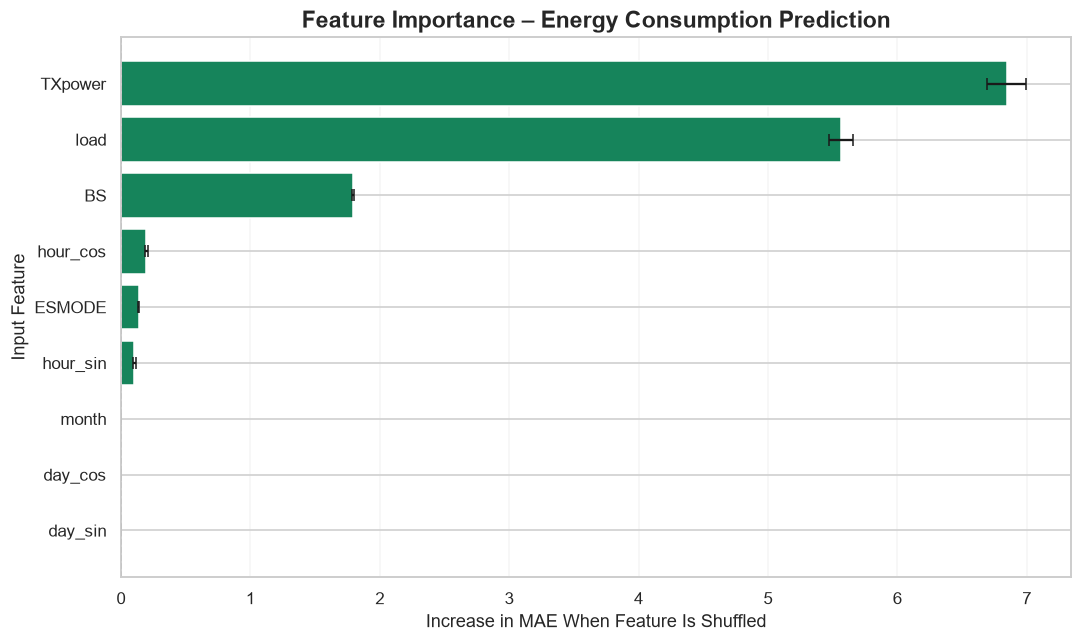

,Feature,Importance,Std
2,TXpower,6.8445,0.1512
0,load,5.5642,0.0958
3,BS,1.7905,0.0072
5,hour_cos,0.1972,0.0102
1,ESMODE,0.1366,0.0059
4,hour_sin,0.1026,0.0128
6,day_sin,0.0000,0.0000
7,day_cos,0.0000,0.0000
8,month,0.0000,0.0000


In [66]:
X_importance = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

y_importance = y_test.loc[X_importance.index]

importance_results = permutation_importance(
    best_model,
    X_importance,
    y_importance,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=6
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_results.importances_mean,
    "Std": importance_results.importances_std
}).sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"],
    color="#16845B",
    capsize=4
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Increase in MAE When Feature Is Shuffled"
)

ax.set_ylabel("Input Feature")

ax.set_title(
    "Feature Importance – Energy Consumption Prediction",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

display(
    importance_df.sort_values(
        "Importance",
        ascending=False
    ).round(4)
)